In [64]:
import copy
from itertools import product
from collections import Counter
import bisect
import os
import pickle
import numpy as np
from operator import itemgetter
from qiskit import QuantumCircuit
from qiskit.circuit import Parameter
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram
from scipy.optimize import minimize
import networkx as nx
import matplotlib.pyplot as plt
from numpy import random
from collections import namedtuple
from qiskit import transpile
from qiskit_ibm_runtime.fake_provider import FakeFez      # pick any fake device with enough qubits
from qiskit_aer.primitives import SamplerV2
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager
from qiskit.primitives import StatevectorSampler

In [65]:
def create_qaoa(graph, num_layers=1):

    #insert edges and nodes
    pqc=QuantumCircuit(n)
    # QAOA circuits start with 
    pqc.h(range(n))

    h = nx.get_node_attributes(graph, "weight")
    J = nx.get_edge_attributes(graph, "weight")
    params={}

    # adding layers 
    for l in range(num_layers):
        
        gamma_label=f'g_{l}'     
        params[gamma_label]= Parameter(gamma_label)    
        
        beta_label=f'b_{l}' 
        params[beta_label]= Parameter(beta_label)    

        pqc.barrier()
        for i in h.keys():
            pqc.rz(h[i]*params[gamma_label], i)
        
        for i, j in J.keys():                
            pqc.cx(i, j)
            pqc.rz(J[i,j]*params[gamma_label], j)
            pqc.cx(i, j)

        #Mixer Hamiltonian
        pqc.barrier()
        for i in range(n):
            pqc.rx(params[beta_label], i)
        
        #end of the layer
        pqc.barrier()

    pqc.measure_all()
    return pqc

def init_params_uni(circuit):
    parameters = random.uniform(-np.pi / 2, np.pi / 2, circuit.num_parameters)
    return parameters

def init_params_lin(circuit):
    parameters = np.linspace(-np.pi / 2, np.pi / 2, circuit.num_parameters)
    return parameters

def init_params_tri(circuit):
    parameters = random.triangular(-np.pi / 2, 0.0, np.pi / 2, circuit.num_parameters)
    return parameters

param_funcs = [init_params_lin, init_params_tri, init_params_uni]

In [66]:
seed = 1224
random.seed(seed)
n = 15

fake_device = FakeFez()                           # local object holding the device's calibration data
noisy_backend = AerSimulator.from_backend(fake_device)   # local simulator with that device's noise model, basis gates and coupling map

sampler = SamplerV2.from_backend(noisy_backend, seed=1224)
pass_manager = generate_preset_pass_manager(optimization_level=1, backend=noisy_backend)

barabasi_albert_g = nx.barabasi_albert_graph(n=n, m=1, seed=seed)

In [67]:
def assign_uniform_weights(graph):
    for u, v in graph.edges():
        graph[u][v]["weight"] = random.uniform(-1,1)
    for node in graph.nodes():
        graph.nodes[node]["weight"] = random.uniform(-1,1)
    return graph

def assign_random_weights(graph):
    seq = [-1,1]
    for u, v in graph.edges():
        graph[u][v]["weight"] = random.choice(seq)
    for node in graph.nodes():
        graph.nodes[node]["weight"] = random.choice(seq)
    return graph

def assign_gauss_weights(graph):
    for u, v in graph.edges():
        graph[u][v]["weight"] = random.normal(loc=0.0, scale=1.0)
    for node in graph.nodes():
        graph.nodes[node]["weight"] = random.normal(loc=0.0, scale=1.0)
    return graph

/tmp/ipykernel_23824/2377321089.py:23: UserWarning: 

The arrowsize keyword argument is not applicable when drawing edges
with LineCollection.

To make this warning go away, either specify `arrows=True` to
force FancyArrowPatches or use the default values.
Note that using FancyArrowPatches may be slow for large graphs.

  nx.draw_networkx_edges(G, pos, width=1.5, edge_color="gray",


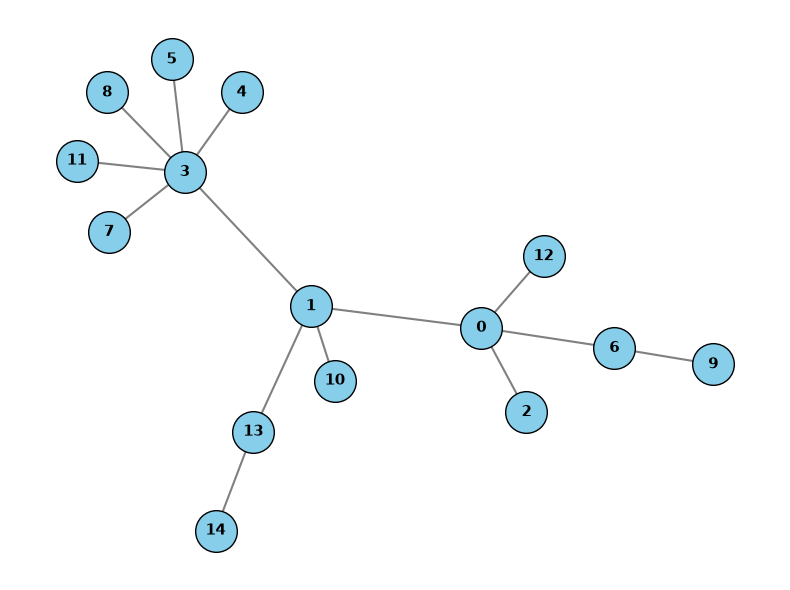

In [68]:
import networkx as nx
import matplotlib.pyplot as plt


def visualize_graph(G, layout="spring", node_color="skyblue", node_size=900,
                    show_weights=True, title=None, save_path=None, seed=42):
    layouts = {
        "spring": lambda g: nx.spring_layout(g, seed=seed),
        "circular": nx.circular_layout,
        "kamada_kawai": nx.kamada_kawai_layout,
        "shell": nx.shell_layout,
        "spectral": nx.spectral_layout,
        "random": lambda g: nx.random_layout(g, seed=seed),
    }
    if layout not in layouts:
        raise ValueError(f"Unknown layout '{layout}'. Choose from {list(layouts)}")
    pos = layouts[layout](G)

    fig, ax = plt.subplots(figsize=(8, 6))

    nx.draw_networkx_nodes(G, pos, node_color=node_color, node_size=node_size,
                           edgecolors="black", ax=ax)
    nx.draw_networkx_edges(G, pos, width=1.5, edge_color="gray",
                           arrows=G.is_directed(), arrowsize=20, ax=ax)
    nx.draw_networkx_labels(G, pos, font_size=11, font_weight="bold", ax=ax)

    # Edge weight labels (skipped for multigraphs, where edges are keyed)
    if show_weights and not G.is_multigraph():
        edge_labels = nx.get_edge_attributes(G, "weight")
        if edge_labels:
            nx.draw_networkx_edge_labels(G, pos, edge_labels=edge_labels, ax=ax)

    if title:
        ax.set_title(title)
    ax.axis("off")
    plt.tight_layout()

    if save_path:
        plt.savefig(save_path, dpi=300, bbox_inches="tight")
        plt.close(fig)
    else:
        plt.show()


# Usage with your own graph:
# visualize_graph(G)
# visualize_graph(G, layout="kamada_kawai", title="My Graph", save_path="graph.png")
visualize_graph(barabasi_albert_g)

In [72]:
assign_uniform_weights(barabasi_albert_g)
edges = barabasi_albert_g.edges(data=True)

In [82]:
# List of (node, degree) sorted by degree, highest first
def sort_stats(graph):
    sorted_degrees = sorted(graph.degree(), key=lambda x: x[1], reverse=True)

    neighbors_by_weight = {
        n: sorted(
            ((nbr, data.get("weight", 1)) for nbr, data in graph[n].items()),
            key=lambda x: abs(x[1]),
            reverse=False,
        )
        for n in graph
    }

    return sorted_degrees, neighbors_by_weight

In [83]:
sort_stats(barabasi_albert_g)

([(3, 6),
  (0, 4),
  (1, 4),
  (6, 2),
  (13, 2),
  (2, 1),
  (4, 1),
  (5, 1),
  (7, 1),
  (8, 1),
  (9, 1),
  (10, 1),
  (11, 1),
  (12, 1),
  (14, 1)],
 {0: [(1, -0.17503705297235772),
   (12, -0.250709024606139),
   (2, -0.380633525891785),
   (6, -0.761337925130732)],
  1: [(0, -0.17503705297235772),
   (13, -0.27039689845041925),
   (10, 0.5300244352021457),
   (3, 0.9222039200759218)],
  2: [(0, -0.380633525891785)],
  3: [(5, -0.10020038179602642),
   (4, -0.32833938215770697),
   (8, 0.4697227303002218),
   (7, -0.4715548750079108),
   (11, 0.9037124288721219),
   (1, 0.9222039200759218)],
  4: [(3, -0.32833938215770697)],
  5: [(3, -0.10020038179602642)],
  6: [(0, -0.761337925130732), (9, 0.9492528835428073)],
  7: [(3, -0.4715548750079108)],
  8: [(3, 0.4697227303002218)],
  9: [(6, 0.9492528835428073)],
  10: [(1, 0.5300244352021457)],
  11: [(3, 0.9037124288721219)],
  12: [(0, -0.250709024606139)],
  13: [(14, -0.23616547558650502), (1, -0.27039689845041925)],
  14: [(1

In [ ]:
def ordered_remove_edge(graph, sorted_degrees, neighbors_by_weight, num_edges, num_nodes):
    for i in range(0, num_nodes):
        node = sorted_degrees[i][0]
        elim = min(sorted_degrees[i][1], num_edges)

        for j in range(0, elim):
            graph.remove_edge(node, neighbors_by_weight[node][j][0])

    return graph


def random_remove_edge(graph, sorted_degrees, neighbors_by_weight, num_edges, num_nodes):
    for i in range(0, num_nodes):
        node = sorted_degrees[i][0]
        elim = min(sorted_degrees[i][1], num_edges)
        choose = []

        for j in range(0, len(neighbors_by_weight[node])):
            choose.append(neighbors_by_weight[node][j][0])

        for j in range(0, elim):
            graph.remove_edge(node, choose.pop(random.randrange(len(choose))))
            
    return graph


In [ ]:
all_graphs = []
key = []
original_graphs = []
for pref in range(1, 4):
    temp_graph = nx.barabasi_albert_graph(n=n, m=pref, seed=seed)
    original_graphs.append(temp_graph)
    weighted_graph = assign_uniform_weights(copy.deepcopy(temp_graph))
    degrees, neighbors = sort_stats(weighted_graph)
    all_graphs.append(weighted_graph)
    key.append(pref, "uniform", "original", 0, 0)
    
    for nodes in range(1, 4):
        for edges in range(1, 4):
            all_graphs.append(ordered_remove_edge(copy.deepcopy(temp_graph)))
            key.append(pref, "uniform", "ordered", nodes, edges)

            all_graphs.append(random_remove_edge(copy.deepcopy(temp_graph)))
            key.append(pref, "uniform", "random", nodes, edges)

In [ ]:
# 1. Backend and connectivity graph
coupling_map = fake_device.coupling_map            # CouplingMap (directed edge list)

G = nx.Graph()
G.add_nodes_from(range(fake_device.num_qubits))    # keeps any isolated qubits
G.add_edges_from(coupling_map.get_edges())     # duplicates (a,b)/(b,a) merge in an undirected Graph

print(f"{G.number_of_nodes()} qubits, {G.number_of_edges()} couplings")

# 2. Nodes sorted by degree (highest first, ties broken by qubit index)
sorted_degrees = sorted(G.degree(), key=lambda x: (-x[1], x[0]))
for q, d in sorted_degrees:
    print(f"qubit {q}: degree {d}")

In [ ]:
results_path = "qaoa_noisy_results.pkl"

# Load earlier progress if the file exists
if os.path.exists(results_path):
    with open(results_path, "rb") as file:
        all_results = pickle.load(file)
else:
    all_results = []

completed_run_keys = {
    (r["graph_index"], r["num_layers"], r["init_name"]) for r in all_results
}


def save_results():
    temporary_path = results_path + ".tmp"
    with open(temporary_path, "wb") as file:
        pickle.dump(all_results, file)
    os.replace(temporary_path, results_path)     # swap in only after the write finished


for graph_index, graph in enumerate(all_graphs):
    h = nx.get_node_attributes(graph, "weight")
    J = nx.get_edge_attributes(graph, "weight")
    n = graph.number_of_nodes()

    all_bitstrings = ["".join(b) for b in product("01", repeat=n)]
    all_costs = [f(bits, h, J) for bits in all_bitstrings]
    exact_global_minimum = min(all_costs)
    exact_best_bitstring = all_bitstrings[int(np.argmin(all_costs))]

    for num_layers in range(1, 11):
        logical_pqc = create_qaoa(graph=graph, num_layers=num_layers)
        pqc = pass_manager.run(logical_pqc)

        circuit_stats = {
            "logical_depth": logical_pqc.depth(),
            "logical_two_qubit_gates": logical_pqc.num_nonlocal_gates(),
            "transpiled_depth": pqc.depth(),
            "transpiled_two_qubit_gates": pqc.num_nonlocal_gates(),
            "transpiled_gate_counts": dict(pqc.count_ops()),
        }

        for init_param in param_funcs:
            run_key = (graph_index, num_layers, init_param.__name__)
            if run_key in completed_run_keys:
                continue                                   # finished in an earlier session
            print(
                f"Simulating graph {graph_index + 1}/{len(all_graphs)} | "
                f"layers {num_layers}/5 | init {init_param.__name__} | "
                f"{n} qubits, {pqc.num_parameters} parameters, depth {pqc.depth()}"
            )


            x0 = init_param(pqc)
            evaluations = []

            def logged_objective(angles):
                counts = (
                    sampler.run([pqc.assign_parameters(angles)], shots=1024)
                    .result()[0].data.meas.get_counts()
                )
                counts = {b[::-1]: c for b, c in counts.items()}
                ev = sum(f(b, h, J) * c for b, c in counts.items()) / sum(counts.values())
                evaluations.append({"angles": np.array(angles), "ev": ev, "counts": counts})
                return ev

            result = minimize(logged_objective, x0, method="COBYLA", options={"maxiter": 200})

            all_results.append({
                "graph_index": graph_index,
                "num_layers": num_layers,
                "init_name": init_param.__name__,
                "parameter_names": [p.name for p in pqc.parameters],
                "x0": x0,
                "result": result,
                "evaluations": evaluations,
                "all_bitstrings": all_bitstrings,
                "all_costs": all_costs,
                "exact_global_minimum": exact_global_minimum,
                "exact_best_bitstring": exact_best_bitstring,
                **circuit_stats
            })
            completed_run_keys.add(run_key)
            save_results()                                 # checkpoint after every run